In [1]:
from functools import partial

import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

from torchgeo_bench.coordbench.datasets import (
    load_chelsa_monthly, load_daily_usa_electric_usage, load_era5_ecmwf)
from torchgeo_bench.coordbench.models import ClimplicitLocationEncoder, TemporalSatCLIPEncoder
from torchgeo_bench.coordbench.probe import linear_probe_score
from torchgeo_bench.coordbench.spatiotemporal_idw import find_knn_and_predict
from torchgeo_bench.coordbench.splits import spatial_fold_ids
from torchgeo_bench.coordbench.temporal_aggregation import DAY_SECONDS

In [2]:
DEVICE = "cuda"
KS = (1, 5, 10, 20, 50)
CS = (0.0, 1e-20, 1e-18, 1e-16, 1e-15, 1e-14, 1e-13, 1e-12, 1e-10)

In [3]:
elec = load_daily_usa_electric_usage(subsample_locations=True)[0]
era5 = load_era5_ecmwf(subsample_locations=True)[0]
chelsa = load_chelsa_monthly(subsample_locations=True)[0]

/u/lbetti/projects/torchgeo-bench/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:394: RuntimeWarning: divide by zero encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:394: RuntimeWarning: divide by zero encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:394: RuntimeWarning: invalid value encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))


# Data Prep

In [4]:
def prep(b, target, subsample_N=None, seed=0):
    rng = np.random.default_rng(seed)
    valid = np.where((b.lat >= -60) & np.isfinite(b.tasks[target]))[0]
    n = len(valid) if subsample_N is None else min(subsample_N, len(valid))
    idx = np.sort(rng.choice(valid, n, replace=False))
    return dict(name=b.name, lat=b.lat[idx], lon=b.lon[idx],
                t=np.asarray(b.posix_timestamp[idx], dtype=np.float64),
                tasks={target: b.tasks[target][idx]})


In [5]:
data = (
    [prep(elec, t) for t in elec.tasks]
    + [prep(era5, "t2m")]
    + [prep(chelsa, "hurs")]
)


## Splits

In [6]:
def random_split(d, frac=0.2, seed=0):
    return np.random.default_rng(seed).random(len(d["lat"])) < frac

def spatial_split(d, fold=0, folds=5, cell_deg=10.0, seed=0):
    return spatial_fold_ids(d["lat"], d["lon"], folds, cell_deg, seed) == fold

def checkerboard_split(d, block="monthly"):
    """Alternating time blocks (same parity rules as temporal_aggregation.spin_up_checkerboard)."""
    dates = pd.to_datetime(d["t"], unit="s")
    week = np.asarray(dates.to_period("W-SUN").astype("int64"))
    index = {
        "daily": np.floor(d["t"] / DAY_SECONDS),
        "weekly": week,
        "monthly": dates.year * 12 + dates.month,
        "seasonal": week // 13,
        "yearly": dates.year,
        "2_year": dates.year // 2,
        "4_year": dates.year // 4,
    }[block]
    return np.asarray(index) % 2 == 0


In [7]:
SPLITS = {
    "random": random_split,
    "spatial": spatial_split,
    "temporal_monthly": partial(checkerboard_split, block="monthly"),
    "temporal_seasonally": partial(checkerboard_split, block="seasonal"),
    "temporal_yearly": partial(checkerboard_split, block="yearly"),
}

In [8]:
def make_masks(d, splits=SPLITS):
    masks = {}
    for name, fn in splits.items():
        te = fn(d)
        if 0 < te.sum() < len(te):
            masks[name] = te
        else:
            print(f"skipping {name} on {d['name']}: empty train or test set")
    return masks

# IDW

In [9]:
def idw_grid(d, split, te, ks=KS, cs=CS, device=DEVICE):
    """Test R² for every (k, c) with raw time (time_fn=None)."""
    tr = ~te
    rows = []
    for task, y in d["tasks"].items():
        for c in cs:
            p = find_knn_and_predict(
                d["lat"][tr], d["lon"][tr], d["t"][tr], y[tr],
                d["lat"][te], d["lon"][te], d["t"][te],
                ks, "regression", 0, c, device=device, time_fn=None)
            rows += [dict(dataset=d["name"], task=task, split=split, method="idw", k=k, c=c,
                          r2=r2_score(y[te], p[k])) for k in ks]
    return rows

def probe_rows(d, split, te, X, method, device=DEVICE):
    """Ridge probe on precomputed features X, scored on the held-out mask."""
    return [dict(dataset=d["name"], task=task, split=split, method=method, k=np.nan, c=np.nan,
                 r2=linear_probe_score(X, y, "regression", test_mask=te, device=device)[0])
            for task, y in d["tasks"].items()]

def run_all(data, encoders, splits=SPLITS):
    """Embed each dataset once per encoder, then evaluate every split."""
    rows = []
    for d in data:
        feats = {name: enc.encode(d["lon"], d["lat"], d["t"]) for name, enc in encoders.items()}
        for split, te in make_masks(d, splits).items():
            rows += idw_grid(d, split, te)
            rows += [r for name, X in feats.items() for r in probe_rows(d, split, te, X, name)]
    return pd.DataFrame(rows)


In [10]:
import os
os.environ["SATCLIP_HOME"] = os.path.expanduser("~/projects/temporal-satclip")
os.environ["CKPT_HOME"] = os.path.expanduser("/projects/bgtj/t_satclip/ckpts/")

In [14]:
encoders = {
    "t-satclip": TemporalSatCLIPEncoder(
        ckpt_path="/projects/bgtj/t_satclip/ckpts/t_satclip-ckpts/tsatclip-doy-1M.ckpt",
        model_name="tsatclip/doy",
        device=DEVICE,
    ),
    "climplicit": ClimplicitLocationEncoder(device=DEVICE),
}


using pretrained moco vit16
using loss function: satclip_loss
using temporal model: True


In [15]:
res = run_all(data, encoders)

skipping temporal_yearly on usa_daily_electric_load_2016_from_centroid: empty train or test set


/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)


skipping temporal_yearly on usa_daily_electric_load_2016_from_centroid: empty train or test set


/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)


skipping temporal_yearly on era5_ecmwf: empty train or test set


/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:225: UserWarning: ridge

# Results

In [16]:
KEYS = ["dataset", "task", "split"]

def summary(res):
    """Encoders vs the best (k, c) of IDW, per split."""
    idw = res[res.method == "idw"]
    best = idw.loc[idw.groupby(KEYS).r2.idxmax()].assign(method="idw (best k,c)")
    return (pd.concat([res[res.method != "idw"], best])
              .pivot_table(index=["dataset", "task"], columns=["split", "method"], values="r2")
              .round(3))

def idw_table(res, split):
    """R² over the (k, c) grid for one split."""
    return (res.query("method == 'idw' and split == @split")
               .pivot_table(index=["dataset", "task", "k"], columns="c", values="r2").round(3))

summary(res)

split                                                     random  \
method                                                climplicit   
dataset                                    task                    
chelsa                                     hurs            0.907   
era5_ecmwf                                 t2m             0.942   
usa_daily_electric_load_2016_from_centroid median          0.104   
                                           median_log      0.225   

split                                                                 \
method                                                idw (best k,c)   
dataset                                    task                        
chelsa                                     hurs                0.881   
era5_ecmwf                                 t2m                 0.979   
usa_daily_electric_load_2016_from_centroid median              0.979   
                                           median_log          0.989   

split                                                              spatial  \
method                                                t-satclip climplicit   
dataset                                    task                              
chelsa                                     hurs           0.725      0.883   
era5_ecmwf                                 t2m            0.891      0.945   
usa_daily_electric_load_2016_from_centroid median         0.287     -0.015   
                                           median_log     0.411     -0.165   

split                                                                 \
method                                                idw (best k,c)   
dataset                                    task                        
chelsa                                     hurs                0.735   
era5_ecmwf                                 t2m                 0.930   
usa_daily_electric_load_2016_from_centroid median             -0.170   
                                           median_log         -0.716   

split                                                            \
method                                                t-satclip   
dataset                                    task                   
chelsa                                     hurs           0.580   
era5_ecmwf                                 t2m            0.851   
usa_daily_electric_load_2016_from_centroid median        -0.030   
                                           median_log    -0.550   

split                                                 temporal_monthly  \
method                                                      climplicit   
dataset                                    task                          
chelsa                                     hurs                  0.907   
era5_ecmwf                                 t2m                   0.943   
usa_daily_electric_load_2016_from_centroid median               -0.059   
                                           median_log            0.004   

split                                                                 \
method                                                idw (best k,c)   
dataset                                    task                        
chelsa                                     hurs                0.876   
era5_ecmwf                                 t2m                 0.934   
usa_daily_electric_load_2016_from_centroid median              0.976   
                                           median_log          0.984   

split                                                            \
method                                                t-satclip   
dataset                                    task                   
chelsa                                     hurs           0.726   
era5_ecmwf                                 t2m            0.889   
usa_daily_electric_load_2016_from_centroid median         0.297   
                                           median_log     0.405   

sp

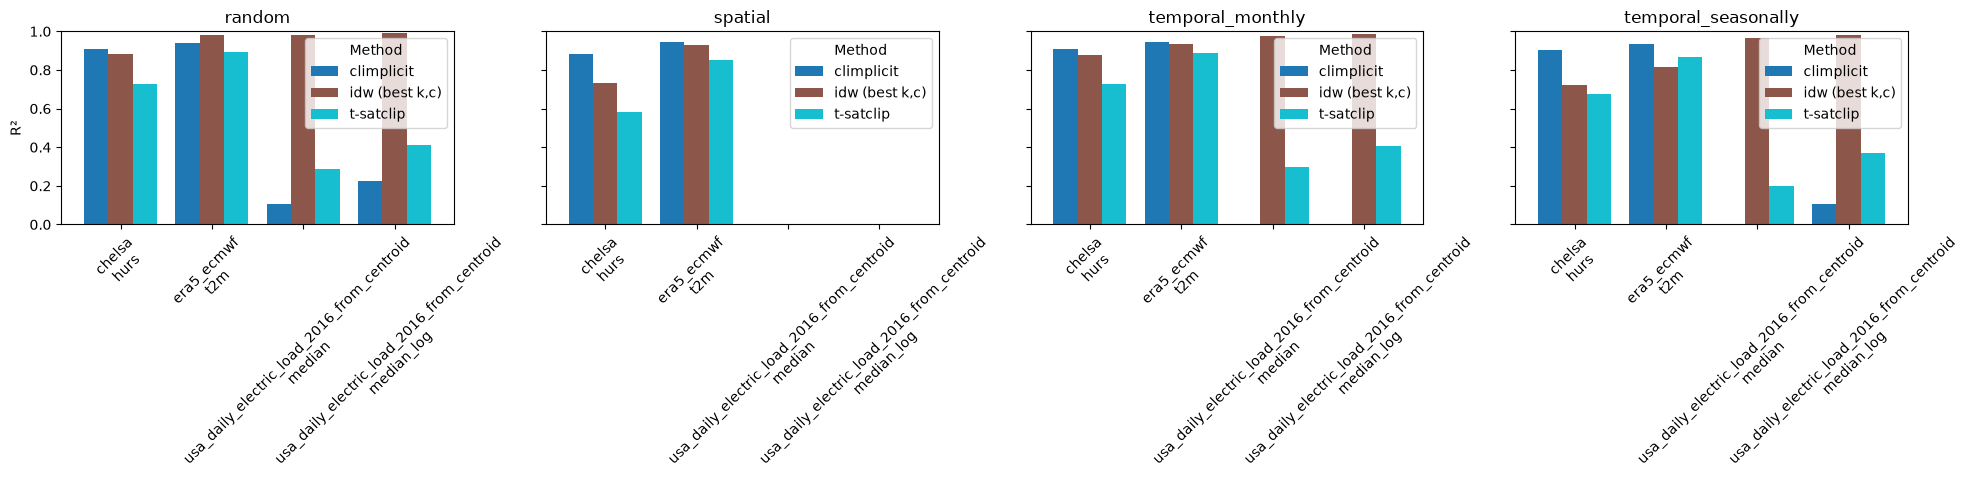

In [17]:
import matplotlib.pyplot as plt

def plot_summary(res):
    df = summary(res).drop(columns="temporal_yearly", level="split")
    df = df.where(df >= 0)
    df.index = [f"{d}\n{t}" for d, t in df.index]

    splits = df.columns.get_level_values("split").unique()
    fig, axes = plt.subplots(1, len(splits), figsize=(5 * len(splits), 5), sharey=True)

    for ax, split in zip(axes, splits):
        df[split].plot.bar(ax=ax, width=0.8, colormap="tab10")
        ax.set(title=split, xlabel="", ylabel="R²", ylim=(0, 1))
        ax.tick_params(axis="x", rotation=45)
        ax.legend(title="Method")

    plt.tight_layout()
    plt.show()

plot_summary(res)